<a href="https://colab.research.google.com/github/Deven-Syndicate/ML-Learning/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [70]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models

In [71]:
df = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

In [72]:
df.sample(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
7999,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
40309,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38463,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
23239,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
30659,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [73]:
df_test.sample(5)

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
14065,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
24510,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5581,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10885,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8941,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [74]:
df.shape

(42000, 785)

In [75]:
df_test.shape

(28000, 784)

In [76]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [78]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel779,0
pixel780,0
pixel781,0
pixel782,0


In [79]:
X = pd.DataFrame(df.drop("label", axis=1))
y = pd.DataFrame(df["label"])

In [80]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)


In [81]:
X_train = X_train.values
y_train = y_train.values
X_test = X_test.values
y_test = y_test.values

In [82]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [83]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

In [84]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [85]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")
])

In [86]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

In [87]:
history_percp = perceptron.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7709 - loss: 1.0058 - val_accuracy: 0.8505 - val_loss: 0.6415
Epoch 2/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8641 - loss: 0.5623 - val_accuracy: 0.8692 - val_loss: 0.5110
Epoch 3/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8778 - loss: 0.4779 - val_accuracy: 0.8764 - val_loss: 0.4582
Epoch 4/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8869 - loss: 0.4365 - val_accuracy: 0.8822 - val_loss: 0.4277
Epoch 5/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8919 - loss: 0.4106 - val_accuracy: 0.8851 - val_loss: 0.4076


In [88]:
acc_percp = perceptron.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [89]:
acc_percp

0.885064959526062

**ANN**

In [90]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [91]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [92]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9036 - loss: 0.3325 - val_accuracy: 0.9437 - val_loss: 0.1840
Epoch 2/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9589 - loss: 0.1378 - val_accuracy: 0.9617 - val_loss: 0.1273
Epoch 3/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9717 - loss: 0.0916 - val_accuracy: 0.9642 - val_loss: 0.1168
Epoch 4/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9783 - loss: 0.0693 - val_accuracy: 0.9688 - val_loss: 0.1005
Epoch 5/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9841 - loss: 0.0503 - val_accuracy: 0.9584 - val_loss: 0.1348


In [93]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [94]:
acc_ann

0.9584415555000305

In [95]:
X_train_cnn = X_train.reshape(-1, 28, 28,1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

**CNN**

In [96]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [97]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [98]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 36s 39ms/step - accuracy: 0.8972 - loss: 0.3251 - val_accuracy: 0.9765 - val_loss: 0.0801
Epoch 2/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - accuracy: 0.9662 - loss: 0.1160 - val_accuracy: 0.9801 - val_loss: 0.0598
Epoch 3/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9753 - loss: 0.0812 - val_accuracy: 0.9852 - val_loss: 0.0490
Epoch 4/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9785 - loss: 0.0681 - val_accuracy: 0.9865 - val_loss: 0.0421
Epoch 5/5
880/880 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step - accuracy: 0.9831 - loss: 0.0546 - val_accuracy: 0.9864 - val_loss: 0.0457


In [99]:
acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]

In [100]:
acc_cnn

0.9864357709884644

In [101]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

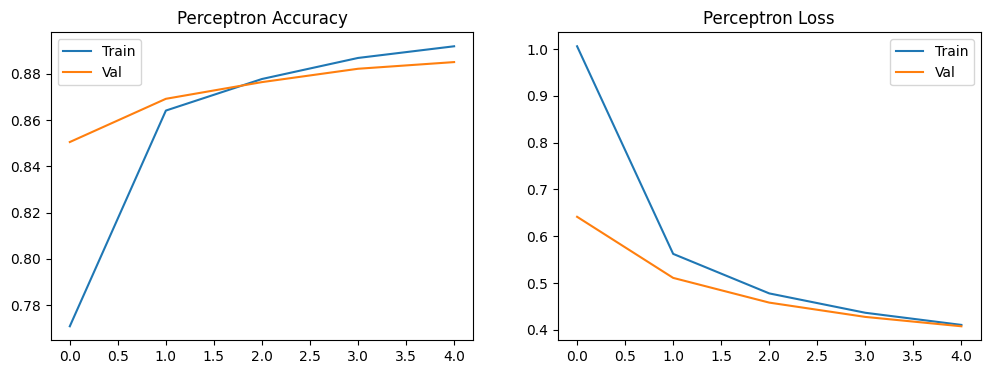

In [102]:
plot_training(history_percp, "Perceptron")

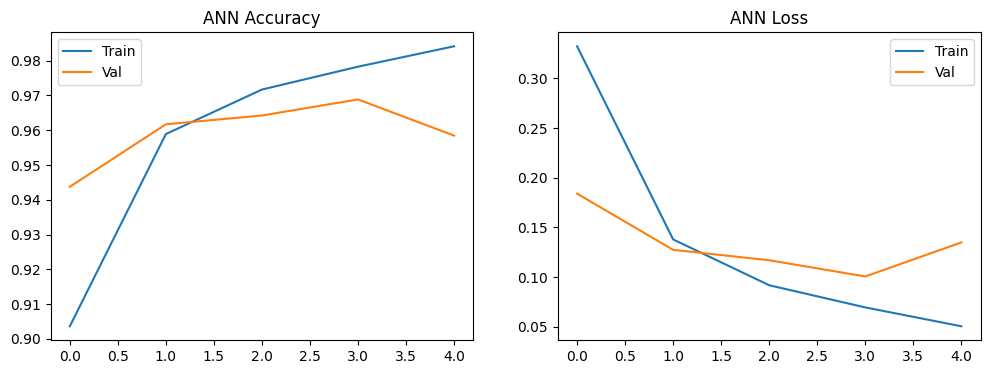

In [103]:
plot_training(history_ann, "ANN")

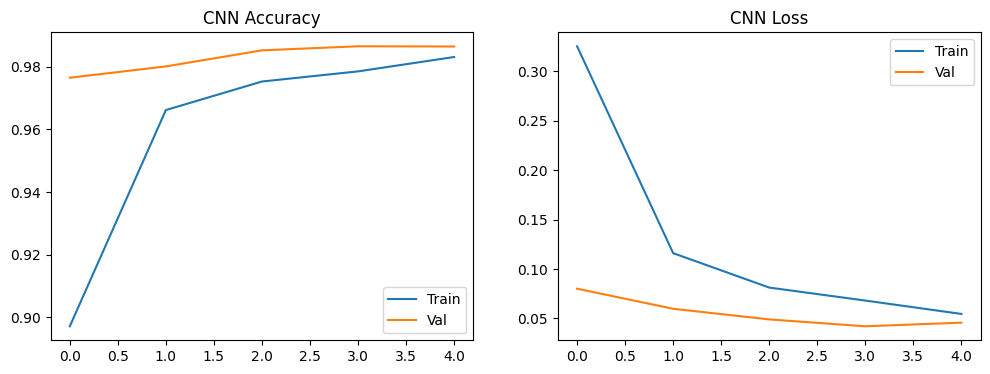

In [104]:
plot_training(history_cnn, "CNN")

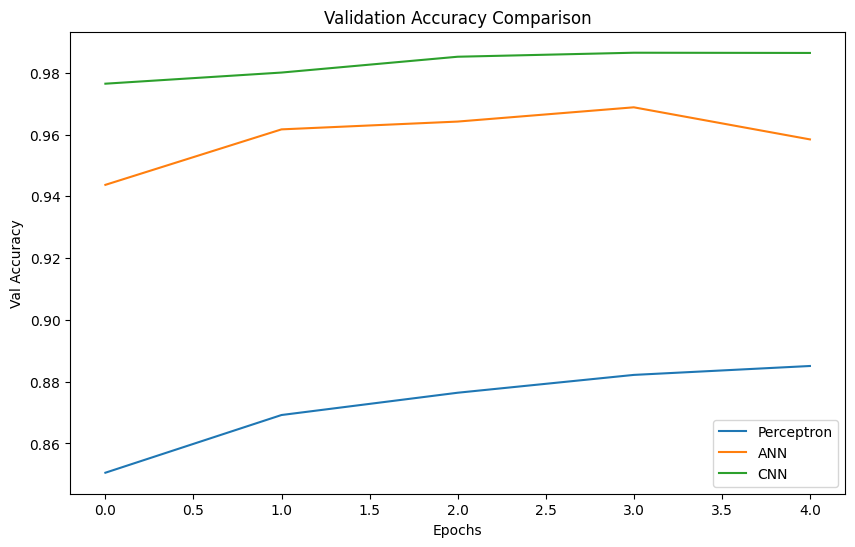

In [105]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [106]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


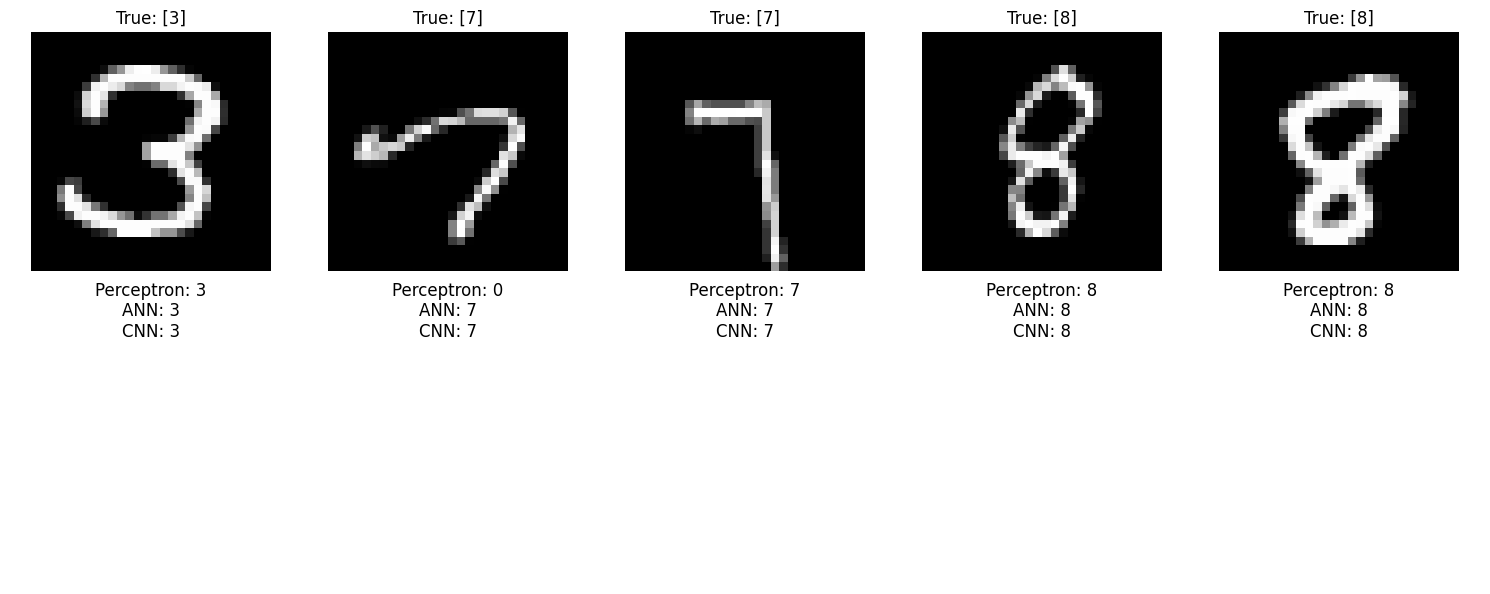

In [107]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

434/434 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step


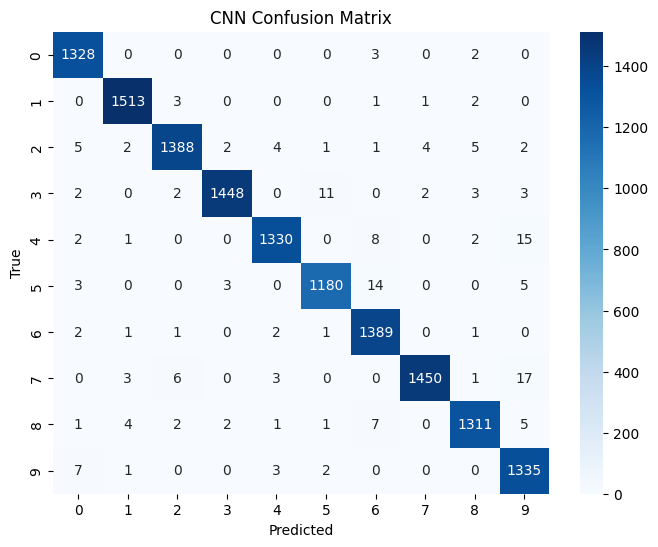

In [108]:
y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

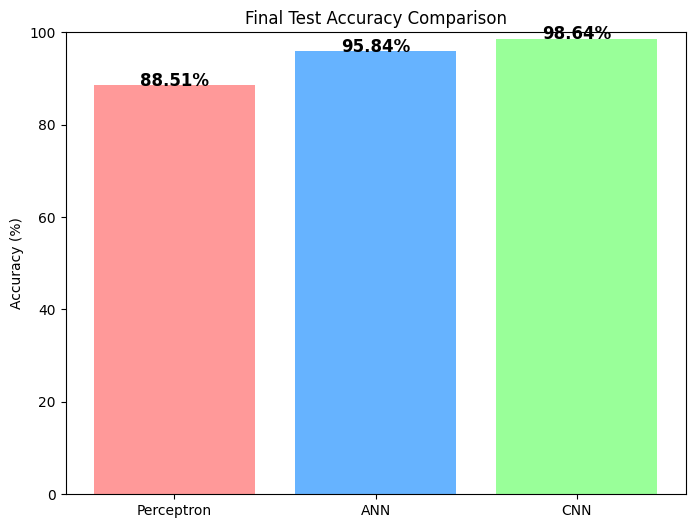

In [111]:
final_accs = [acc_percp*100, acc_ann*100, acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(0, 100)
plt.show()